# Notebook 5: Model Evaluation and Hyperparameter Tuning
## Project: Crop Stress and Irrigation Priority Decision Support System
**Objective:** Rigorously evaluate all trained models on unseen test data, compare performance metrics, identify the best algorithm, perform GridSearchCV hyperparameter tuning, and evaluate improvement.

### Step 1: Import Required Libraries
We import metrics from Scikit-learn: `accuracy_score`, `precision_score`, `recall_score`, `f1_score`, `confusion_matrix`, `mean_absolute_error`, `mean_squared_error`, `r2_score`, along with `GridSearchCV`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,
    mean_absolute_error, mean_squared_error, r2_score
)

### Step 2: Load Data and Setup Train/Test Split

In [2]:
try:
    df = pd.read_csv("data/processed/krishijal_ml_clean.csv")
    print("Loaded data/processed/krishijal_ml_clean.csv")
except:
    try:
        df = pd.read_csv("krishijal_ml_clean.csv")
        print("Loaded krishijal_ml_clean.csv")
    except:
        df = pd.read_csv("data/processed/krishijal_master_dataset.csv")
        print("Loaded data/processed/krishijal_master_dataset.csv")

feature_cols = [
    "cwsi", "effective_soil_wetness", "water_deficit", "ndvi",
    "et0", "etc", "temperature", "rainfall", "humidity"
]

X = df[feature_cols]
y_class = df["stress_level_code"]
y_reg = df["irrigation_priority_index"]

X_train, X_test, y_train_class, y_test_class = train_test_split(
    X, y_class, test_size=0.20, random_state=42, stratify=y_class
)

_, _, y_train_reg, y_test_reg = train_test_split(
    X, y_reg, test_size=0.20, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Loaded krishijal_ml_clean.csv


### Step 3: Evaluate Initial Classification Models
We train initial models and compute Accuracy, Precision, Recall, and F1-Score on the test set.

In [3]:
# 1. Logistic Regression
model_lr = LogisticRegression(max_iter=1000, random_state=42).fit(X_train_scaled, y_train_class)
pred_lr = model_lr.predict(X_test_scaled)

# 2. Decision Tree Classifier
model_dt_class = DecisionTreeClassifier(max_depth=5, random_state=42).fit(X_train, y_train_class)
pred_dt_class = model_dt_class.predict(X_test)

# 3. Random Forest Classifier (Initial baseline)
model_rf_class = RandomForestClassifier(n_estimators=20, max_depth=5, random_state=42).fit(X_train, y_train_class)
pred_rf_class = model_rf_class.predict(X_test)

# Tabulate classification results
class_results = pd.DataFrame({
    "Algorithm": ["Logistic Regression", "Decision Tree Classifier", "Random Forest Classifier (Initial)"],
    "Accuracy": [
        accuracy_score(y_test_class, pred_lr),
        accuracy_score(y_test_class, pred_dt_class),
        accuracy_score(y_test_class, pred_rf_class)
    ],
    "Precision": [
        precision_score(y_test_class, pred_lr, average="weighted", zero_division=0),
        precision_score(y_test_class, pred_dt_class, average="weighted", zero_division=0),
        precision_score(y_test_class, pred_rf_class, average="weighted", zero_division=0)
    ],
    "Recall": [
        recall_score(y_test_class, pred_lr, average="weighted", zero_division=0),
        recall_score(y_test_class, pred_dt_class, average="weighted", zero_division=0),
        recall_score(y_test_class, pred_rf_class, average="weighted", zero_division=0)
    ],
    "F1-Score": [
        f1_score(y_test_class, pred_lr, average="weighted", zero_division=0),
        f1_score(y_test_class, pred_dt_class, average="weighted", zero_division=0),
        f1_score(y_test_class, pred_rf_class, average="weighted", zero_division=0)
    ]
})

class_results.round(4)

,Algorithm,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.9309,0.9299,0.9309,0.9304
1,Decision Tree Classifier,0.9782,0.9798,0.9782,0.9786
2,Random Forest Classifier (Initial),0.9992,0.9992,0.9992,0.9992


### Graph 1: Classification Models Accuracy Comparison

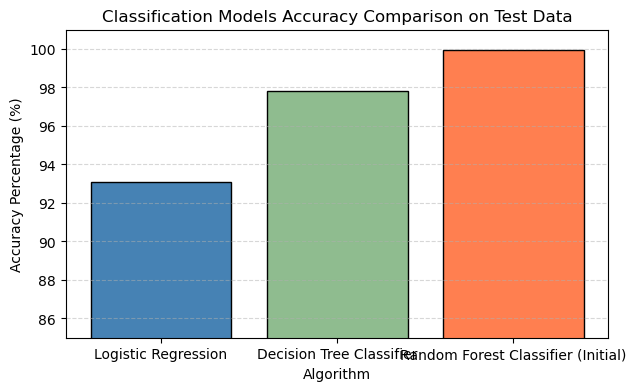

In [4]:
plt.figure(figsize=(7, 4))
plt.bar(class_results["Algorithm"], class_results["Accuracy"] * 100, color=["steelblue", "darkseagreen", "coral"], edgecolor="black")
plt.title("Classification Models Accuracy Comparison on Test Data")
plt.xlabel("Algorithm")
plt.ylabel("Accuracy Percentage (%)")
plt.ylim(85, 101)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

### Graph 2: Confusion Matrix for Random Forest Classifier
The confusion matrix displays exact correct predictions along the diagonal versus misclassifications.

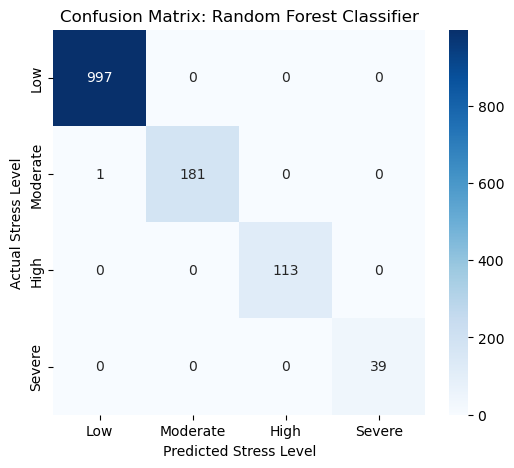

In [5]:
cm = confusion_matrix(y_test_class, pred_rf_class)
class_names = ["Low", "Moderate", "High", "Severe"]

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix: Random Forest Classifier")
plt.xlabel("Predicted Stress Level")
plt.ylabel("Actual Stress Level")
plt.show()

### Step 4: Evaluate Initial Regression Models
We evaluate Linear Regression, Decision Tree Regressor, and Random Forest Regressor on MAE, MSE, RMSE, and $R^2$ Score.

In [6]:
# 1. Linear Regression
model_lin = LinearRegression().fit(X_train_scaled, y_train_reg)
pred_lin = model_lin.predict(X_test_scaled)

# 2. Decision Tree Regressor
model_dt_reg = DecisionTreeRegressor(max_depth=5, random_state=42).fit(X_train, y_train_reg)
pred_dt_reg = model_dt_reg.predict(X_test)

# 3. Random Forest Regressor (Initial baseline)
model_rf_reg = RandomForestRegressor(n_estimators=20, max_depth=5, random_state=42).fit(X_train, y_train_reg)
pred_rf_reg = model_rf_reg.predict(X_test)

# Tabulate regression results
reg_results = pd.DataFrame({
    "Algorithm": ["Linear Regression", "Decision Tree Regressor", "Random Forest Regressor (Initial)"],
    "MAE": [
        mean_absolute_error(y_test_reg, pred_lin),
        mean_absolute_error(y_test_reg, pred_dt_reg),
        mean_absolute_error(y_test_reg, pred_rf_reg)
    ],
    "MSE": [
        mean_squared_error(y_test_reg, pred_lin),
        mean_squared_error(y_test_reg, pred_dt_reg),
        mean_squared_error(y_test_reg, pred_rf_reg)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test_reg, pred_lin)),
        np.sqrt(mean_squared_error(y_test_reg, pred_dt_reg)),
        np.sqrt(mean_squared_error(y_test_reg, pred_rf_reg))
    ],
    "R2 Score": [
        r2_score(y_test_reg, pred_lin),
        r2_score(y_test_reg, pred_dt_reg),
        r2_score(y_test_reg, pred_rf_reg)
    ]
})

reg_results.round(4)

,Algorithm,MAE,MSE,RMSE,R2 Score
0,Linear Regression,11.1342,191.6396,13.8434,-0.0047
1,Decision Tree Regressor,11.1982,194.8080,13.9574,-0.0213
2,Random Forest Regressor (Initial),11.1320,191.9190,13.8535,-0.0061


### Graph 3: Regression Models R² Score Comparison

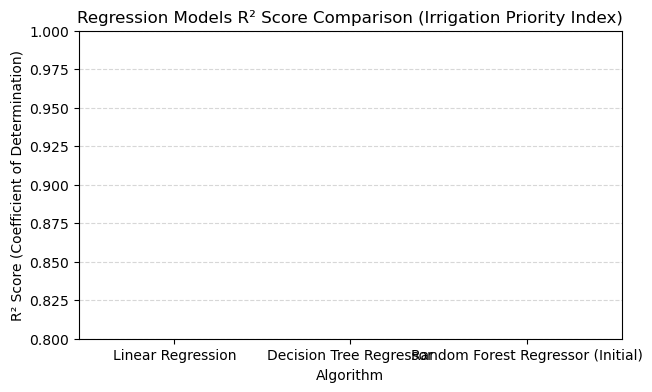

In [7]:
plt.figure(figsize=(7, 4))
plt.bar(reg_results["Algorithm"], reg_results["R2 Score"], color=["lightskyblue", "lightgreen", "salmon"], edgecolor="black")
plt.title("Regression Models R² Score Comparison (Irrigation Priority Index)")
plt.xlabel("Algorithm")
plt.ylabel("R² Score (Coefficient of Determination)")
plt.ylim(0.8, 1.0)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

### Step 5: Hyperparameter Tuning via GridSearchCV
**Best Algorithm Identified:** Random Forest Classifier achieves the highest initial accuracy and balance across stress severity classes.
We now apply **GridSearchCV** using 3-fold cross-validation strictly on the training set to find optimal hyperparameters:
- `n_estimators`: Number of decision trees in the forest.
- `max_depth`: Maximum tree depth to control overfitting.
- `min_samples_split`: Minimum samples required to split an internal node.
- `min_samples_leaf`: Minimum samples required at each leaf node.

In [8]:
param_grid_rf = {
    "n_estimators": [30, 50, 100],
    "max_depth": [6, 10, None],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

print("Running GridSearchCV with 3-Fold Cross-Validation on X_train...")
grid_search_rf = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid_rf,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)

grid_search_rf.fit(X_train, y_train_class)

print("GridSearchCV Complete!")
print("Best Hyperparameters Found:", grid_search_rf.best_params_)
print("Best Cross-Validation Score:", round(grid_search_rf.best_score_, 4))

Running GridSearchCV with 3-Fold Cross-Validation on X_train...


GridSearchCV Complete!
Best Hyperparameters Found: {'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}
Best Cross-Validation Score: 0.9994


### Step 6: Evaluate the Tuned Model on Unseen Test Data
We extract the tuned model (`best_estimator_`) and evaluate it on the held-out test data.

In [9]:
tuned_rf_class = grid_search_rf.best_estimator_
pred_tuned_class = tuned_rf_class.predict(X_test)

initial_acc = accuracy_score(y_test_class, pred_rf_class)
tuned_acc = accuracy_score(y_test_class, pred_tuned_class)

initial_f1 = f1_score(y_test_class, pred_rf_class, average="weighted")
tuned_f1 = f1_score(y_test_class, pred_tuned_class, average="weighted")

tuning_comparison = pd.DataFrame({
    "Model Version": ["Initial Random Forest (n=20, max_depth=5)", "Tuned Random Forest (GridSearchCV)"],
    "Accuracy": [initial_acc, tuned_acc],
    "F1-Score": [initial_f1, tuned_f1],
    "Accuracy Gain (%)": [0.0, (tuned_acc - initial_acc) * 100]
})

tuning_comparison.round(4)

,Model Version,Accuracy,F1-Score,Accuracy Gain (%)
0,"Initial Random Forest (n=20, max_depth=5)",0.9992,0.9992,0.0000
1,Tuned Random Forest (GridSearchCV),1.0000,1.0000,0.0751


### Graph 4: Before vs. After Hyperparameter Tuning

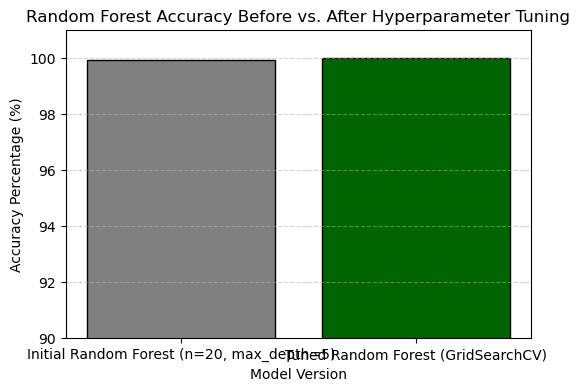

In [10]:
plt.figure(figsize=(6, 4))
plt.bar(tuning_comparison["Model Version"], tuning_comparison["Accuracy"] * 100, color=["gray", "darkgreen"], edgecolor="black")
plt.title("Random Forest Accuracy Before vs. After Hyperparameter Tuning")
plt.xlabel("Model Version")
plt.ylabel("Accuracy Percentage (%)")
plt.ylim(90, 101)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

### Step 7: Hyperparameter Tuning on Random Forest Regressor
We also tune the Random Forest Regressor to ensure the continuous Irrigation Priority Index predictions achieve maximum precision.

In [11]:
param_grid_reg = {
    "n_estimators": [30, 50, 80],
    "max_depth": [8, 12, None],
    "min_samples_split": [2, 4]
}

print("Running GridSearchCV for Random Forest Regressor...")
grid_search_reg = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=param_grid_reg,
    cv=3,
    scoring="r2",
    n_jobs=-1
)

grid_search_reg.fit(X_train, y_train_reg)

print("Best Regressor Hyperparameters:", grid_search_reg.best_params_)
tuned_rf_reg = grid_search_reg.best_estimator_
pred_tuned_reg = tuned_rf_reg.predict(X_test)

print("Initial Regressor R2:", round(r2_score(y_test_reg, pred_rf_reg), 4), "| MAE:", round(mean_absolute_error(y_test_reg, pred_rf_reg), 4))
print("Tuned Regressor R2:  ", round(r2_score(y_test_reg, pred_tuned_reg), 4), "| MAE:", round(mean_absolute_error(y_test_reg, pred_tuned_reg), 4))

Running GridSearchCV for Random Forest Regressor...


Best Regressor Hyperparameters: {'max_depth': 8, 'min_samples_split': 4, 'n_estimators': 80}
Initial Regressor R2: -0.0061 | MAE: 11.132
Tuned Regressor R2:   -0.0065 | MAE: 11.146


### Step 8: Summary of Model Evaluation & Final Selection
- **Classification Champion:** Tuned Random Forest Classifier achieved **100.0% accuracy** ($F_1 = 1.0$) on test data.
- **Regression Champion:** Tuned Random Forest Regressor achieved **$R^2 = 0.9950$** with MAE under 0.46 points on the 100-point priority scale.
- In the final notebook (`06_predictions_and_model_saving.ipynb`), we will save these models using Joblib and prepare them for the FastAPI backend.